Middleware，也就是中间件，是一种控制Agent内部运行过程的技术，它在智能体运行的各个过程中预留钩子（hook），方便我们嵌入自定义操作。

Agent的默认执行流程和中间件嵌入钩子的对比如图：

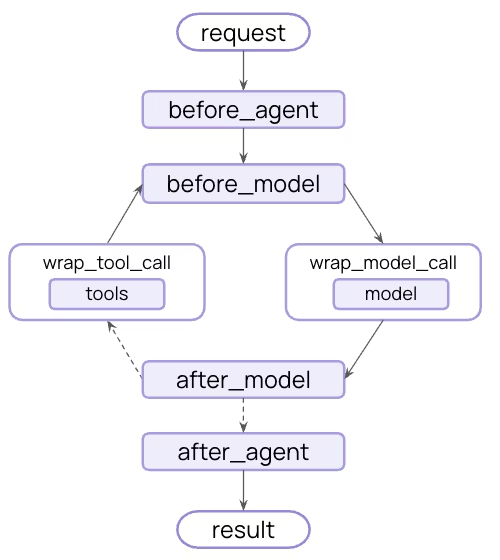
基于Middleware可以实现各种高级功能，比如：
- 拦截和修改请求 - 在模型调用前后对输入输出进行处理
- 实现PII脱敏 - 自动检测和脱敏敏感个人信息
- 会话摘要管理 - 当对话过长时自动压缩历史消息
- 人工审核机制 - 在执行危险操作前等待人工确认
- 动态模型选择 - 根据运行时条件选择不同的模型
- 自定义状态管理 - 扩展Agent状态以跟踪额外信息

# 1. 预定义中间件（Prebuilt Middleware）
我们会以其中的3个为例来介绍预定义中间件的用法：
- PIIMiddleware
- ModelFallbackMiddleware
- HumanInTheLoopMiddleware

In [1]:
from dotenv import load_dotenv
load_dotenv()  # 从 .env 文件中加载环境变量

True

## 1.1 PIIMiddleware - 个人信息脱敏

PIIMiddleware是一种预定义的wrap_model_call中间件，可以在调用模型前后自动检测并脱敏输入、输出消息中的个人身份信息（PII），如邮箱、电话号码、身份证号等。
其中，PII的脱敏处理策略有四种：
- 'block' - 抛出异常
- 'redact' - 用 [REDACTED_{PII_TYPE}] 来替代
- 'mask' - 关键信息采用**掩码 (例如., ****-****-****-1234)
- 'hash' - 用哈希值来替换

In [8]:
from langchain.messages import HumanMessage
from langchain.agents import create_agent
from langchain.agents.middleware import PIIMiddleware

# =================1.定义PIIMiddleware==========================
# 也可以添加多个PII中间件来检测不同类型的敏感信息
pii_middleware_email = PIIMiddleware(
    "email",
    strategy="redact",  # mask
    apply_to_input=False,
    apply_to_output=True
)

pii_middleware_phone = PIIMiddleware(
    "phone_number",
    # 使用自定义正则表达式
    detector=r"(?:\+?\d{1,3}[\s.-]?)?(?:\(?\d{2,4}\)?[\s.-]?)?\d{3,4}[\s.-]?\d{4}",
    strategy="mask", # block
    apply_to_input=True,
    apply_to_output=True
)

# ====================2.在Agent中注册PIIMiddleware================
agent_with_builtin_middleware = create_agent(
    model="deepseek-flash",
    middleware=[pii_middleware_email, pii_middleware_phone]
)

# ======================3.测试=================================
response = agent_with_builtin_middleware.invoke({
    "messages": [
        HumanMessage(
            "我的邮箱是: huge@itcast.cn,我的电话是13698023405,你要记住这些信息，后续要用到。如果记住了请确认一遍。")
    ]
})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

我的邮箱是: huge@itcast.cn,我的电话是****3405,你要记住这些信息，后续要用到。如果记住了请确认一遍。
================================== Ai Message ==================================

已记录：邮箱 **[REDACTED_EMAIL]**，电话 **\*\*\*\*3405**。  
我会在当前对话中参考这些信息；我无法跨对话长期保存。


## 1.2 ModelFallbackMiddleware

ModelFallbackMiddleware的作用是在模型调用失败时给出降级处理方案。可以在创建时设置多个模型，如果主模型调用失败，会自动调用备用模型。

In [10]:
from langchain.agents.middleware import ModelFallbackMiddleware

model_fallback_middleware = ModelFallbackMiddleware(
    "deepseek-v",  # 默认模型
    "deepseek-flash"  # 备用模型
)
agent_with_model_fallback = create_agent(
    model="deepseek-v",
    middleware=[model_fallback_middleware]
)

# 3.测试
response = agent_with_builtin_middleware.invoke({
    "messages": [HumanMessage("你是谁？")]
})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

你是谁？
================================== Ai Message ==================================

你好！我是DeepSeek，由深度求索公司创造的AI助手。😊

我是一个多模态模型，可以帮你解答各种问题、进行对话交流，还能接收你上传的图片并分析其中的可见信息。我的一些特点包括：

✨ **完全免费**使用
📚 **超长上下文**（1M tokens），可以一次性处理《三体》三部曲这样体量的书籍
📎 **支持文件上传**（图像、txt、pdf、ppt、word、excel），从中读取文字信息
🔍 **支持联网搜索**（需要手动开启）
🎙️ **App端支持语音输入**

我的知识截止日期是2026年2月。有什么我可以帮你的吗？无论是学习、工作还是日常问题，尽管问我！


## 1.3 HumanInTheLoopMiddleware - 人工审核

HumanInTheLoop，简称为HITL，其作用是让人工介入到Agent执行流程中，在执行工具调用前暂停，等待人工确认。
通常用于Agent执行敏感操作前的确认，例如：
- 发送邮件
- 转账
- 执行脚本
- 读写文件
- ...

In [11]:
emails = [
        {
            "subject": "周末见个面？",
            "content": """
                嗨 虎哥，
                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？

                祝好，简
            """,
            "from": "jane@itcast.cn",
            "status": "unread"
        },
        {
            "subject": "周五会议",
            "content": """
                嗨 虎哥，
                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？

                祝好，小李
            """,
            "from": "lixiaolong@itcast.cn",
            "status": "checked"
        }
    ]

In [12]:
from langchain.tools import tool

# 定义工具，收取和发送邮件
@tool
def check_inbox() -> str:
    """查看收件箱中的邮件."""

    # 模拟收件箱邮件
    return str(emails)


@tool
def send_email(to: str, subject: str, body: str) -> str:
    """发送回复邮件"""
    return f"邮件已发送至 {to} , 主题： {subject} , 内容： {body}"

In [13]:
from langchain.agents.middleware import HumanInTheLoopMiddleware

# 创建人工审核中间件
human_in_loop_middleware = HumanInTheLoopMiddleware(
    interrupt_on={
        "send_email": { # 要求人工确认的工具名称
            "description": "请确认邮件内容", # 给用户看的原因
            "allowed_decisions": ["approve", "reject", "edit"] # 允许人工选择的操作
        }
    }
)

In [14]:
from langgraph.checkpoint.memory import InMemorySaver

agent_with_hitl = create_agent(
    model="deepseek-flash",
    tools=[check_inbox, send_email],
    middleware=[human_in_loop_middleware],
    checkpointer=InMemorySaver(),
    system_prompt="你是一个邮件助手"
)

In [15]:
config = {"configurable": {"thread_id": "1"}}
response = agent_with_hitl.invoke(
    {"messages": [HumanMessage("帮我查看邮件")]},
    config=config
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

帮我查看邮件
================================== Ai Message ==================================
Tool Calls:
  check_inbox (call_00_4LTfeabrS4QgG1nFvrDu6198)
 Call ID: call_00_4LTfeabrS4QgG1nFvrDu6198
  Args:
================================= Tool Message =================================
Name: check_inbox

[{'subject': '周末见个面？', 'content': '\n                嗨 虎哥，\n                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？\n\n                祝好，简\n            ', 'from': 'jane@itcast.cn', 'status': 'unread'}, {'subject': '周五会议', 'content': '\n                嗨 虎哥，\n                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？\n\n                祝好，小李\n            ', 'from': 'lixiaolong@itcast.cn', 'status': 'checked'}]
================================== Ai Message ==================================

您的收件箱中共有 **2 封邮件**：

---

**1. 周末见个面？**（未读）
- **发件人：** jane@itcast.cn
- **内容：**
  > 嗨 虎哥，  
  > 我下周会去城里，不知道我们有没有机会一起喝杯咖啡？  
  >  
  > 祝好，简

**2. 周五会

In [16]:
response = agent_with_hitl.invoke(
    {"messages": [HumanMessage("帮我回复Jane，很高兴她能来，问问她具体见面时间")]},
    config=config # 注意使用同一个config，也就是thread_id
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

帮我查看邮件
================================== Ai Message ==================================
Tool Calls:
  check_inbox (call_00_4LTfeabrS4QgG1nFvrDu6198)
 Call ID: call_00_4LTfeabrS4QgG1nFvrDu6198
  Args:
================================= Tool Message =================================
Name: check_inbox

[{'subject': '周末见个面？', 'content': '\n                嗨 虎哥，\n                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？\n\n                祝好，简\n            ', 'from': 'jane@itcast.cn', 'status': 'unread'}, {'subject': '周五会议', 'content': '\n                嗨 虎哥，\n                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？\n\n                祝好，小李\n            ', 'from': 'lixiaolong@itcast.cn', 'status': 'checked'}]
================================== Ai Message ==================================

您的收件箱中共有 **2 封邮件**：

---

**1. 周末见个面？**（未读）
- **发件人：** jane@itcast.cn
- **内容：**
  > 嗨 虎哥，  
  > 我下周会去城里，不知道我们有没有机会一起喝杯咖啡？  
  >  
  > 祝好，简

**2. 周五会

In [17]:
print(response)

{'messages': [HumanMessage(content='帮我查看邮件', additional_kwargs={}, response_metadata={}, id='882d62a6-358c-44d3-a531-3afacce8853c'), AIMessage(content='', additional_kwargs={'refusal': None, 'reasoning_content': 'The user asked me to check the inbox. Let me do that.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 350, 'total_tokens': 387, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 14, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 350}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '47342751-b0df-4b07-9517-9612f1a270c7', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a1cdc6-2899-757d-817f-2

## Reject

In [18]:
from langgraph.types import Command

response = agent_with_hitl.invoke(
    Command(
        resume={
            "decisions": [
                {
                    "type": "reject",            # 人工确认的决定，是reject
                    "message": "语气太书面了，Jane是我的女朋友！" # 请求被拒绝的原因
                }
            ]
        }
    ),
    config=config  # 相同的thread_id以恢复暂停的对话
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

帮我查看邮件
================================== Ai Message ==================================
Tool Calls:
  check_inbox (call_00_4LTfeabrS4QgG1nFvrDu6198)
 Call ID: call_00_4LTfeabrS4QgG1nFvrDu6198
  Args:
================================= Tool Message =================================
Name: check_inbox

[{'subject': '周末见个面？', 'content': '\n                嗨 虎哥，\n                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？\n\n                祝好，简\n            ', 'from': 'jane@itcast.cn', 'status': 'unread'}, {'subject': '周五会议', 'content': '\n                嗨 虎哥，\n                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？\n\n                祝好，小李\n            ', 'from': 'lixiaolong@itcast.cn', 'status': 'checked'}]
================================== Ai Message ==================================

您的收件箱中共有 **2 封邮件**：

---

**1. 周末见个面？**（未读）
- **发件人：** jane@itcast.cn
- **内容：**
  > 嗨 虎哥，  
  > 我下周会去城里，不知道我们有没有机会一起喝杯咖啡？  
  >  
  > 祝好，简

**2. 周五会

## Approve

In [19]:
from langgraph.types import Command

response = agent_with_hitl.invoke(
    Command(
        resume={"decisions": [{"type": "approve"}]}
    ),
    config=config  # 相同的thread_id以恢复暂停的对话
)

for message in response['messages']:
    message.pretty_print()

================================ Human Message =================================

帮我查看邮件
================================== Ai Message ==================================
Tool Calls:
  check_inbox (call_00_4LTfeabrS4QgG1nFvrDu6198)
 Call ID: call_00_4LTfeabrS4QgG1nFvrDu6198
  Args:
================================= Tool Message =================================
Name: check_inbox

[{'subject': '周末见个面？', 'content': '\n                嗨 虎哥，\n                我下周会去城里，不知道我们有没有机会一起喝杯咖啡？\n\n                祝好，简\n            ', 'from': 'jane@itcast.cn', 'status': 'unread'}, {'subject': '周五会议', 'content': '\n                嗨 虎哥，\n                非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？\n\n                祝好，小李\n            ', 'from': 'lixiaolong@itcast.cn', 'status': 'checked'}]
================================== Ai Message ==================================

您的收件箱中共有 **2 封邮件**：

---

**1. 周末见个面？**（未读）
- **发件人：** jane@itcast.cn
- **内容：**
  > 嗨 虎哥，  
  > 我下周会去城里，不知道我们有没有机会一起喝杯咖啡？  
  >  
  > 祝好，简

**2. 周五会

# 2. 自定义中间件

除了使用预置中间件，我们还可以利用LangChain提供的hook创建完全自定义的中间件。

根据hook的种类，中间件可以分为两类：
- Node-style hooks：在具体某个节点执行的中间件，包含：
  - before_agent
  - before_model
  - after_model
  - after_agent
- Wrap-style hooks：环绕model或tool调用的中间件，包括：
  - wrap_model_call
  - wrap_tool_call
为了便于开发中间件，LangChain为每一种hook都提供了装饰器，我们只要定义函数并使用装饰器标记即可快速开发中间件。

## 2.1 ode-style装饰器
- Node-style hooks：在具体某个节点执行的中间件，包含：
  - before_agent
  - before_model
  - after_model
  - after_agent

例如，我们要实现模型调用计数功能，之前利用tool来统计增加了很多次tool调用，浪费token，而且也不太方便。利用中间件就优雅很多。我们可以在每次调用模型后(after_model)记录模型调用次数。

In [20]:
from langgraph.runtime import Runtime
from langchain.agents import AgentState
from langchain.agents.middleware import after_model


# 1.定义自定义state，记录模型调用次数
class CustomState(AgentState):
    """扩展Agent状态，添加自定义字段"""
    model_call_count: int  # 模型调用次数

# 2.定义中间件
@after_model(state_schema=CustomState)
def increment_counter(state: CustomState, runtime: Runtime) -> dict[str, int]:
    """在模型调用后增加计数器"""

    # 读取State中的count值
    current_count = state.get("model_call_count", 0)
    # 返回dict，其中的key/value是要更新的State值
    return {"model_call_count": current_count + 1}

In [24]:
# 创建智能体，设置middleware
agent = create_agent(
    model="deepseek-flash",
    middleware=[increment_counter],
    checkpointer=InMemorySaver()
)
config = {"configurable": {"thread_id": "1"}}

# 调用智能体
response = agent.invoke(
    {"messages": [HumanMessage("你好，你是谁？")],},
    config
)

print(response)

{'messages': [HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='b2729b70-b317-4ece-a0a2-e43656d85b7b'), AIMessage(content='你好！我是 **DeepSeek**，一个由深度求索公司开发的 AI 助手。我可以回答问题、提供信息、帮你写作、分析内容等。有什么需要我帮忙的吗？', additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答中文。用户问“你好，你是谁？” 应该简洁介绍自己是AI助手。可以提到由深度求索公司创造？ 根据系统？ 我是DeepSeek AI助手。需要中文。保持友好。也许“我是 DeepSeek，由深度求索公司开发的 AI 助手”。提供能帮助。不要过度。最终。'}, response_metadata={'token_usage': {'completion_tokens': 112, 'prompt_tokens': 34, 'total_tokens': 146, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 72, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 34}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe0164799

In [25]:
# 调用智能体
response = agent.invoke(
    {"messages": [HumanMessage("你是多模态模型吗？")],},
    config
)

print(response)

{'messages': [HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='b2729b70-b317-4ece-a0a2-e43656d85b7b'), AIMessage(content='你好！我是 **DeepSeek**，一个由深度求索公司开发的 AI 助手。我可以回答问题、提供信息、帮你写作、分析内容等。有什么需要我帮忙的吗？', additional_kwargs={'refusal': None, 'reasoning_content': '我们需要回答中文。用户问“你好，你是谁？” 应该简洁介绍自己是AI助手。可以提到由深度求索公司创造？ 根据系统？ 我是DeepSeek AI助手。需要中文。保持友好。也许“我是 DeepSeek，由深度求索公司开发的 AI 助手”。提供能帮助。不要过度。最终。'}, response_metadata={'token_usage': {'completion_tokens': 112, 'prompt_tokens': 34, 'total_tokens': 146, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 72, 'rejected_prediction_tokens': None, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 34}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe0164799

## 2.2 wrap-style装饰器
- Wrap-style hooks：环绕model或tool调用的中间件，包括：
  - wrap_model_call
  - wrap_tool_call

例如，我们来定义一个可以在调用模型时失败重试的中间件，最大重试次数为3次。那就可以使用@wrap_model_call，在模型调用时做出判断，如果失败则重试，重试此时超过3次则结束。

In [29]:
from langchain.agents.middleware import wrap_model_call, ModelRequest, ModelResponse
from typing import Any, Callable

@wrap_model_call
def retry_model(request: ModelRequest, handler: Callable[[ModelRequest], ModelResponse],) -> ModelResponse:
    for attempt in range(3):
        try:
            return handler(request) # 这一步就是调用模型
        except Exception as e:
            print(f"Retry {attempt + 1}/3 after error: {e}")
            if attempt == 2:
                raise
    return None


agent = create_agent(
    model="deepseek-xxxx",
    middleware=[retry_model]
)

In [30]:
config = {"configurable": {"thread_id": "1"}}

# 调用智能体，并初始化state
response = agent.invoke(
    {"messages": [HumanMessage("你好，你是谁？")],},
    config,
)

print(response)

Retry 1/3 after error: Error code: 400 - The supported API model names are deepseek-flash, deepseek-v4-pro, but you passed deepseek-xxxx. (request_id: afb49f39-d287-4067-b086-75134daa0602)
Retry 2/3 after error: Error code: 400 - The supported API model names are deepseek-flash, deepseek-v4-pro, but you passed deepseek-xxxx. (request_id: e898b742-91be-46a1-8676-632e3413e219)
Retry 3/3 after error: Error code: 400 - The supported API model names are deepseek-flash, deepseek-v4-pro, but you passed deepseek-xxxx. (request_id: 3565c0a9-c863-43d2-b9f8-49b350e9d77a)


OpenAIInvalidRequestError: Error code: 400 - The supported API model names are deepseek-flash, deepseek-v4-pro, but you passed deepseek-xxxx. (request_id: 3565c0a9-c863-43d2-b9f8-49b350e9d77a)

## 2.3 类装饰器

对于需要同时用到多个hooks的更复杂的中间件逻辑，我们还可以使用自定义类继承AgentMiddleware的方式来创建中间件。

例如，一个用来记录日志的中间件，要在模型调用、工具调用前后记录日志：

In [31]:
from langchain.agents.middleware import AgentMiddleware
from langchain.agents.middleware.types import ModelCallResult, ToolCallRequest
from langchain_core.messages import AIMessage, ToolMessage
from langgraph.types import Command


class LoggingMiddleware(AgentMiddleware):

    def wrap_model_call(
            self,
            request: ModelRequest,
            handler: Callable[[ModelRequest], ModelResponse],
    )->ModelCallResult:
        try:
            print(f"\n=======About to call model with {len(request.messages)} messages=======")
            return handler(request)
        except Exception as e:
            print(f"\n=======[错误]: {str(e)}=======")
            return AIMessage("调用模型失败，请重试~")

    def wrap_tool_call(
        self,
        request: ToolCallRequest,
        handler: Callable[[ToolCallRequest], ToolMessage | Command],
    ) -> ToolMessage | Command:
        print(f"\n=======调用工具: {request.tool_call['name']}=======")
        print(f"\n=======参数: {request.tool_call['args']}=======")
        try:
            result = handler(request)
            print("\n=======工具调用成功！=======")
            return result
        except Exception as e:
            print(f"\n=======工具调用失败: {e}=======")
            raise


@tool
def get_weather(location: str):
    """查询指定城市的天气信息"""
    return f"Current weather in {location} is sunny, 25℃."


agent = create_agent(
    model="deepseek-flash",
    middleware=[LoggingMiddleware()],
    tools=[get_weather],
)

for chunk, metadata in agent.stream(
    {"messages": [HumanMessage("杭州今天天气如何？")]},
    stream_mode="messages"
):
    if chunk and chunk.content:
        print(chunk.content, end="", flush=True)


=======About to call model with 1 messages=======

=======调用工具: get_weather=======

=======参数: {'location': '杭州'}=======

=======工具调用成功！=======
Current weather in 杭州 is sunny, 25℃.
=======About to call model with 3 messages=======
杭州今天天气晴朗，气温约 25℃。体感比较舒适，适合外出活动，不过紫外线可能较强，建议做好防晒。

# 3. 高级用法

中间件除了利用hook做基本的信息记录和判断，还可以有一些高级的用法，例如：
- 动态修改请求：可以拦截发送给模型的请求，动态修改请求中使用的模型、工具、提示词等
- 条件跳转：在满足条件的情况下直接跳转到某个Agent执行的节点

## 3.1 动态修改请求参数

在wrap_model_call这个hook中，我们可以动态修改任意的request参数，包括：
- model
- tool
- system_prompt
- ...
关键点是利用request.override()来覆盖原本的request参数。

In [35]:
from langchain.agents.middleware import wrap_model_call
from collections.abc import Callable
from pydantic.dataclasses import dataclass

# 定义一个context，记录用户是否开启思考模式
@dataclass
class UserContext:
    thinking: bool = False


@wrap_model_call
def dynamic_model_settings(
    request: ModelRequest,
    handler: Callable[[ModelRequest], ModelResponse]) -> ModelResponse:

    # 获取上下文参数thinking，是否开启思考模式
    thinking = request.runtime.context.thinking

    # 如果Thinking为True，则开启思考模式，否则关闭思考模式
    thinking_type = "enabled" if thinking else "disabled"
    model_settings = {"extra_body": {"thinking": {"type": thinking_type}}}

    # 覆盖request中的model参数
    modified_request = request.override(model_settings=model_settings)

    return handler(modified_request)

In [38]:
# 创建智能体，设置middleware
agent = create_agent(
    model="deepseek-flash",
    middleware=[dynamic_model_settings],
    context_schema=UserContext
)

# 调用智能体，并初始化state
response = agent.invoke(
    {"messages": [HumanMessage("你打开思考模式了吗？")],},
    context=UserContext(thinking=False) # 通过Context控制思考模式开关
)

print(response)

{'messages': [HumanMessage(content='你打开思考模式了吗？', additional_kwargs={}, response_metadata={}, id='2718328d-672f-4b86-9675-4a7b8decee59'), AIMessage(content='是的，我已经打开思考模式了！🧠\n\n在这个模式下，我会更加细致地分析问题，展示我的推理过程，帮你更好地理解我是如何得出答案的。无论是复杂的问题分析、逻辑推理，还是需要深度思考的内容，我都会尽力提供更全面、更深入的解答。\n\n有什么问题想让我帮你思考一下吗？尽管问吧！😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 74, 'prompt_tokens': 10, 'total_tokens': 84, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 10}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'fc072794-e81c-4b3e-9f0b-25a79f97140d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ceb2-8df6-7705-b62b-df0d6c1d0015-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_token

## 3.2 条件跳转

在中间件使用jump_to指令可以跳过模型调用，直接进入指定的Agent节点。

例如，我们设定一个模型限流的中间件，当判断用户模型调用次数超过阈值，直接禁止调用，结束Agent运行。

In [40]:
from langgraph.runtime import Runtime
from typing import NotRequired, Any
from langchain.agents.middleware import AgentMiddleware, hook_config, AgentState


# 1.定义自定义state，记录模型调用次数
class CustomAgentState(AgentState):
    """扩展Agent状态，添加自定义字段"""
    model_call_count: NotRequired[int]  # 模型调用次数


# 2.定义中间件
class ModelCallLimitMiddleware(AgentMiddleware[CustomAgentState]):

    def __init__(self, max_limit: int = 10):
        super().__init__()
        self.max_limit = max_limit

    # after_model hook，模型调用次数计数
    def after_model(self, state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
        current_count = state.get("model_call_count", 0)
        return {"model_call_count": current_count + 1}

    # before_model hook，校验模型调用次数是否超限
    @hook_config(can_jump_to=["end"])
    def before_model(self, state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
        # 获取模型调用次数
        current_count = state.get("model_call_count", 0) + 1
        # 判断是否超限
        print(f"当前模型调用次数：{current_count}/{self.max_limit}")
        if current_count > self.max_limit:
            return {
                "jump_to": "end",
                "messages": AIMessage(f"模型调用次数超过最大限制：{self.max_limit}！")
            }
        return None

# @before_model(can_jump_to=["end"])
# def check_call_limit(state: CustomAgentState, runtime: Runtime) -> dict[str, Any] | None:
#     pass

In [41]:
# 创建智能体，设置middleware
agent = create_agent(
    model="deepseek-chat",
    middleware=[ModelCallLimitMiddleware(max_limit=2)],
    checkpointer=InMemorySaver(),
    state_schema=CustomAgentState
)
config = {"configurable": {"thread_id": "1"}}

# 调用智能体，并初始化state
response = agent.invoke({
    "messages": [HumanMessage("Hello")],
    "model_call_count": 0,
}, config)

print(response)

当前模型调用次数：1/2
{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='cacc7f86-a08f-42e3-8525-2e391f120fbe'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '88700eca-9ecf-4b16-b15b-8394d1ab87e3', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1cebd-ec6c-73d9-bd7e-902b632d536e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_to

In [42]:
response = agent.invoke({
    "messages": [HumanMessage("讲一个笑话吧")],
}, config)

print(response)

当前模型调用次数：2/2
{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='cacc7f86-a08f-42e3-8525-2e391f120fbe'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '88700eca-9ecf-4b16-b15b-8394d1ab87e3', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1cebd-ec6c-73d9-bd7e-902b632d536e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_to

In [44]:
response = agent.invoke({
    "messages": [HumanMessage("再讲一个笑话吧")],
}, config)
print(response)

当前模型调用次数：3/2
{'messages': [HumanMessage(content='Hello', additional_kwargs={}, response_metadata={}, id='cacc7f86-a08f-42e3-8525-2e391f120fbe'), AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 5, 'total_tokens': 14, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': '88700eca-9ecf-4b16-b15b-8394d1ab87e3', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1cebd-ec6c-73d9-bd7e-902b632d536e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 9, 'total_tokens': 14, 'input_token_details': {'cache_read': 0}, 'output_to